In [83]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time

In [84]:
filename = "damage_data7.csv"
df = pd.read_csv(filename, header=0, sep=',')
#print('Are ther any Nan value?:\n', np.isnan(df).any())
# ignore rows which contain zero
# ignore_zero = df[(df['Strain']==0) | (df['Stress']==0) | (df['Temp']==0) | (df['Rate']==0)]
#df=pd.concat([df, ignore_zero, ignore_zero]).drop_duplicates(keep=False)
df.head()

,Geom0,Disp0,Force0,Geom1,Disp1,Force1,Geom2,Disp2,Force2,Geom3,...,Triax0,Lode0,Triax1,Lode1,Triax2,Lode2,Triax3,Lode3,Triax4,Lode4
0,1,1.91105,8.92105,2,0.0,0.0,3,0.0,0.0,4,...,0.516687,0.581692,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1.71835,9.13433,2,0.0,0.0,3,0.0,0.0,4,...,0.710432,0.466943,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,2.38966,7.36185,2,0.0,0.0,3,0.0,0.0,4,...,0.932440,0.131247,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,2.06188,8.62037,2,0.0,0.0,3,0.0,0.0,4,...,0.981092,0.255470,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1,2.27274,7.94911,2,0.0,0.0,3,0.0,0.0,4,...,0.787820,0.232551,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [85]:
df1 = round(df,6)

## Preprocessing

In [86]:
df.columns

Index(['Geom0', 'Disp0', 'Force0', 'Geom1', 'Disp1', 'Force1', 'Geom2',
       'Disp2', 'Force2', 'Geom3', 'Disp3', 'Force3', 'Geom4', 'Disp4',
       'Force4', 'D1', 'D2', 'D3', 'D4', 'Triax0', 'Lode0', 'Triax1', 'Lode1',
       'Triax2', 'Lode2', 'Triax3', 'Lode3', 'Triax4', 'Lode4'],
      dtype='object')

In [87]:
df['D1'].min()

0.03

In [88]:
# apply scaling
df_scaled = pd.DataFrame()
disp_range = np.array([0, 2.6])
force_range = np.array([0, 10])
s_max_range = np.array([821.064, 2669.76])
s_mid_range = np.array([53.9087, 1678.56]) 
s_min_range = np.array([8.36831, 1104.41])
peeq_range = np.array([0.0656731, 1.92155])
triax_range = np.array([0, 2.20036])
lode_range = np.array([-0.501816, 0.986])
geom_range = np.array([1,5])
d1_range = np.array([0.03, 2.9])
d2_range = np.array([0.09, 2.98])
d3_range = np.array([0.1, 2.92])
d4_range = np.array([0.05, 2.96])


def manual_scaling(feat, range_value):
    return (feat - range_value[0])/(range_value[1] - range_value[0])
def manual_descaling(feat, range_value): # inverse of the function above
    return (feat * (range_value[1] - range_value[0])) + range_value[0]

#col_ranges = {'Disp': disp_range,
#              'Force': force_range,
#              'S_max': s_max_range,
#              'S_mid': s_mid_range,
#              'S_min': s_min_range,
#              'Peeq': peeq_range,
#              'Triax': triax_range,
#              'Lode': lode_range,
#              'D1': d1_range,
#              'D2': d2_range,
#              'D3': d3_range,
#              'D4': d4_range}

col_ranges = {'Disp0': disp_range,
              'Force0': force_range,
              'Geom0': geom_range,
              'Disp1': disp_range,
              'Force1': force_range,
              'Geom1': geom_range,
              'Disp2': disp_range,
              'Force2': force_range,
              'Geom2': geom_range,
              'Disp3': disp_range,
              'Force3': force_range,
              'Geom3': geom_range,
              'Disp4': disp_range,
              'Force4': force_range,
              'Geom4': geom_range,
              'D1': d1_range,
              'D2': d2_range,
              'D3': d3_range,
              'D4': d4_range,
              'Triax0': triax_range,
              'Lode0': lode_range,
              'Triax1': triax_range,
              'Lode1': lode_range,
              'Triax2': triax_range,
              'Lode2': lode_range,
              'Triax3': triax_range,
              'Lode3': lode_range,
              'Triax4': triax_range,
              'Lode4': lode_range,}

inp_col_ranges = {'Geom0': geom_range,
                  'Disp0': disp_range,
                  'Force0': force_range,
                  'Geom1': geom_range,
                  'Disp1': disp_range,
                  'Force1': force_range,
                  'Geom2': geom_range,
                  'Disp2': disp_range,
                  'Force2': force_range,
                  'Geom3': geom_range,
                  'Disp3': disp_range,
                  'Force3': force_range,
                  'Geom4': geom_range,
                  'Disp4': disp_range,
                  'Force4': force_range,
               }

for column, col_range in col_ranges.items():
    df_scaled[column] = manual_scaling(df[column], col_range)
    
df_scaled.head()

,Disp0,Force0,Geom0,Disp1,Force1,Geom1,Disp2,Force2,Geom2,Disp3,...,Triax0,Lode0,Triax1,Lode1,Triax2,Lode2,Triax3,Lode3,Triax4,Lode4
0,0.735019,0.892105,0.0,0.0,0.0,0.25,0.0,0.0,0.5,0.0,...,0.234819,0.728254,0.0,0.337284,0.0,0.337284,0.0,0.337284,0.0,0.337284
1,0.660904,0.913433,0.0,0.0,0.0,0.25,0.0,0.0,0.5,0.0,...,0.322871,0.651128,0.0,0.337284,0.0,0.337284,0.0,0.337284,0.0,0.337284
2,0.919100,0.736185,0.0,0.0,0.0,0.25,0.0,0.0,0.5,0.0,...,0.423767,0.425498,0.0,0.337284,0.0,0.337284,0.0,0.337284,0.0,0.337284
3,0.793031,0.862037,0.0,0.0,0.0,0.25,0.0,0.0,0.5,0.0,...,0.445878,0.508992,0.0,0.337284,0.0,0.337284,0.0,0.337284,0.0,0.337284
4,0.874131,0.794911,0.0,0.0,0.0,0.25,0.0,0.0,0.5,0.0,...,0.358041,0.493587,0.0,0.337284,0.0,0.337284,0.0,0.337284,0.0,0.337284


In [89]:
inp_col_ranges = {'Geom0': geom_range,
                  'Disp0': disp_range,
                  'Force0': force_range,
                  'Geom1': geom_range,
                  'Disp1': disp_range,
                  'Force1': force_range,
                  'Geom2': geom_range,
                  'Disp2': disp_range,
                  'Force2': force_range,
                  'Geom3': geom_range,
                  'Disp3': disp_range,
                  'Force3': force_range,
                  'Geom4': geom_range,
                  'Disp4': disp_range,
                  'Force4': force_range
               }

In [90]:
df_scaled = round(df_scaled,6)

In [91]:
out_col_ranges = {'D1': d1_range,
              'D2': d2_range,
              'D3': d3_range,
              'D4': d4_range}

In [92]:
df_scaled

,Disp0,Force0,Geom0,Disp1,Force1,Geom1,Disp2,Force2,Geom2,Disp3,...,Triax0,Lode0,Triax1,Lode1,Triax2,Lode2,Triax3,Lode3,Triax4,Lode4
0,0.735019,0.892105,0.0,0.000000,0.000000,0.25,0.000000,0.000000,0.5,0.000000,...,0.234819,0.728254,0.000000,0.337284,0.000000,0.337284,0.000000,0.337284,0.0,0.337284
1,0.660904,0.913433,0.0,0.000000,0.000000,0.25,0.000000,0.000000,0.5,0.000000,...,0.322871,0.651128,0.000000,0.337284,0.000000,0.337284,0.000000,0.337284,0.0,0.337284
2,0.919100,0.736185,0.0,0.000000,0.000000,0.25,0.000000,0.000000,0.5,0.000000,...,0.423767,0.425498,0.000000,0.337284,0.000000,0.337284,0.000000,0.337284,0.0,0.337284
3,0.793031,0.862037,0.0,0.000000,0.000000,0.25,0.000000,0.000000,0.5,0.000000,...,0.445878,0.508992,0.000000,0.337284,0.000000,0.337284,0.000000,0.337284,0.0,0.337284
4,0.874131,0.794911,0.0,0.000000,0.000000,0.25,0.000000,0.000000,0.5,0.000000,...,0.358041,0.493587,0.000000,0.337284,0.000000,0.337284,0.000000,0.337284,0.0,0.337284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,0.884723,0.790913,0.0,0.673381,0.820104,0.25,0.584504,0.832429,0.5,0.530842,...,0.346512,0.499892,0.355221,0.454918,0.249263,0.487287,0.000000,0.337284,0.0,0.337284
90,0.875112,0.800823,0.0,0.673381,0.820104,0.25,0.576819,0.843459,0.5,0.515492,...,0.334998,0.517637,0.369594,0.423858,0.357783,0.430866,0.000000,0.337284,0.0,0.337284
91,0.884727,0.790914,0.0,0.663762,0.831535,0.25,0.569135,0.853722,0.5,0.553954,...,0.000000,0.337284,0.343404,0.469605,0.277530,0.397227,0.280322,0.476874,0.0,0.337284
92,0.884723,0.790914,0.0,0.654146,0.842120,0.25,0.553742,0.872282,0.5,0.592396,...,0.396192,0.459049,0.332113,0.485595,0.330234,0.461072,0.169834,0.974133,0.0,0.337284


## Decompose features and labels

In [93]:
#feature_columns = ['Disp', 'Force', 'S_max', 'S_mid', 'S_min', 'Peeq', 'Triax', 'Lode']
feature_columns = ['Geom0', 'Disp0', 'Force0', 'Geom1', 'Disp1', 'Force1', 'Geom2', 'Disp2', 'Force2', 'Geom3', 'Disp3', 'Force3', 'Geom4', 'Disp4', 'Force4']
label_columns = ['D1', 'D2', 'D3', 'D4']

df_features = pd.DataFrame()
df_labels = pd.DataFrame()

for col in feature_columns:
    df_features[col] = df_scaled[col]
    
for col in label_columns:
    df_labels[col] = df_scaled[col]

In [94]:
X = df_features.to_numpy()
y = df_labels.to_numpy()

In [95]:
print(X.shape)
print(y.shape)

(94, 15)
(94, 4)


## Decompose train and test set

In [96]:
from sklearn.model_selection import train_test_split

In [97]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=96, test_size=0.1)

In [98]:
print(X_train.shape)
print(X_test.shape)

(84, 15)
(10, 15)


## ANN

In [99]:
from keras.layers import Dense
from keras.models import Sequential
from keras.wrappers.scikit_learn import KerasRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from scipy import stats
from scipy.stats import randint as sp_randint
import tensorflow as tf

In [100]:
# utility function to report best scores
def report(results, n_top=3):
    for i in range(1, n_top + 1):
        candidates = np.flatnonzero(results['rank_test_score'] == i)
        for candidate in candidates:
            print("Model with rank: {0}".format(i))
            print("Mean validation score: {0:.3f} (std: {1:.3f})".format(
                  results['mean_test_score'][candidate],
                  results['std_test_score'][candidate]))
            print("Parameters: {0}".format(results['params'][candidate]))
            print("")

In [101]:
arr = df_scaled.to_numpy()

In [102]:
def create_loss_function(arr):
    def custom_loss(y_true, y_pred):
        
        model_loss = tf.reduce_mean(tf.square(y_true - y_pred))
        
        d1_true = y_true[:,0]
        d2_true = y_true[:,1]
        d3_true = y_true[:,2]
        d4_true = y_true[:,3]

        d1_pred = y_pred[:,0]
        d2_pred = y_pred[:,1]
        d3_pred = y_pred[:,2]
        d4_pred = y_pred[:,3]
        
        mse_list = []
        
        tf_scaled = tf.constant(arr, dtype=tf.float32)
     
        for i in range(y_true.shape[0]):
            d1t = d1_true[i]
            d2t = d1_true[i]
            d3t = d1_true[i]
            d4t = d1_true[i]

            d1p = d1_pred[i]
            d2p = d1_pred[i]
            d3p = d1_pred[i]
            d4p = d1_pred[i]
                
            condition = tf.reduce_all(tf.equal(tf_scaled[:, 15:19], [d1_true[i], d2_true[i], d3_true[i], d4_true[i]]), axis=1)
            selected_row = tf.boolean_mask(tf_scaled, condition)
            mse_list1 = []
            for j in range(5):
                triax = selected_row[:,19+j*2]
                lode = selected_row[:,20+j*2]

                peeq_true = (d1t * tf.exp(-d2t*triax) - (d3t*tf.exp(-d4t*triax))) * lode**2 + d3t*tf.exp(-d4t*triax)    
                peeq_pred = (d1p * tf.exp(-d2p*triax) - (d3p*tf.exp(-d4p*triax))) * lode**2 + d3p*tf.exp(-d4p*triax) 

                ms_err = (peeq_true - peeq_pred)**2
                mse_list.append(ms_err)
                j = j+1
           
            #mse_list.append(ms_err)
            
        loss = tf.reduce_mean(mse_list)

        return (loss + model_loss)

    return custom_loss


In [103]:
import tensorflow.python.ops.numpy_ops.np_config as np_config

In [104]:
np_config.enable_numpy_behavior()

In [105]:
def ANNmodel(hid_layers=[], in_dim=1, out_dim=4):
    model = Sequential()
    if len(hid_layers) == 0:
        model.add(Dense(out_dim, input_dim=in_dim, activation='relu', kernel_initializer='normal'))
    elif len(hid_layers) == 1:
        model.add(Dense(in_dim, input_dim=in_dim, activation='relu', 
                        kernel_initializer='normal'))
        model.add(Dense(out_dim))
    else:
        model.add(Dense(hid_layers[0], input_dim=in_dim, activation='relu', 
                        kernel_initializer='normal'))
        for layer in hid_layers[1:]:
            model.add(Dense(layer, activation='relu'))
        model.add(Dense(out_dim))
    loss_function = create_loss_function(arr)
    model.compile(loss=loss_function, optimizer='adam', run_eagerly=True)
    return model

def get_hid_layers(min_layers=0, max_layers=5, min_neurons=1, max_neurons=10, n_iter=1):
    hid_layers = []
    for _ in range(n_iter):
        layers = np.random.randint(min_layers, max_layers)
        hid_layers.append(np.random.randint(low=min_neurons, high=max_neurons, size=layers).tolist())
    return hid_layers

In [106]:
#train
runANN = False
np.random.seed(99)
n_iter = 50
param_dist = {'hid_layers': get_hid_layers(max_layers=6, min_neurons=1, 
                                           max_neurons=20, n_iter=n_iter)}

if runANN:
    ann = KerasRegressor(build_fn=ANNmodel, in_dim=X_train.shape[1], 
                         epochs=200, batch_size=16, verbose=0)
    random_search_ann = GridSearchCV(estimator=ann, param_grid=param_dist, 
                                     scoring='neg_mean_squared_error')
    start = time.time()
    random_search_ann.fit(X_train, y_train)
    elapsed_ann = (time.time() - start)
    print("RandomizedSearchCV took %.2f seconds for %d candidates"
          " parameter settings." % (elapsed_ann, n_iter))
    report(random_search_ann.cv_results_)

In [107]:
# test
runANN = False 
if runANN:
    best_ann = random_search_ann.best_estimator_
else:
    best_ann_param =  {'hid_layers': [18, 14, 17, 19]} 
    best_ann = KerasRegressor(build_fn=ANNmodel, in_dim=X.shape[1],
                              epochs=200, batch_size=8, verbose=0, **best_ann_param)
start = time.time()
history=best_ann.fit(X, y)
elapsed_ann_test = (time.time() - start)
print('r2_score for training set:', r2_score(y, best_ann.predict(X)))
print("ANN took %.2f seconds for test." % (elapsed_ann_test))

r2_score for training set: 0.411711429279249
ANN took 941.70 seconds for test.


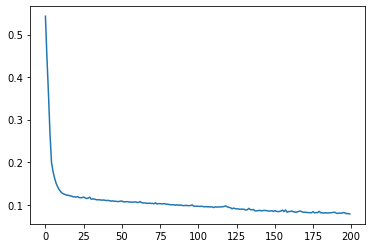

In [108]:
plt.plot(history.history['loss'])

### Predicting Optimal Parameter Sets

In [109]:
inp = np.array([[1, 2.27355, 8.0538, 2, 1.6914, 8.345219, 3, 1.37666, 8.690144, 4, 1.27861, 9.25452, 5, 2.01798, 3.113823]])

In [110]:
inp_df = pd.DataFrame(inp)
inp_df.columns = ['Geom0', 'Disp0', 'Force0', 'Geom1', 'Disp1', 'Force1', 'Geom2', 'Disp2', 'Force2', 'Geom3', 'Disp3', 'Force3', 'Geom4', 'Disp4', 'Force4']
inp_df

,Geom0,Disp0,Force0,Geom1,Disp1,Force1,Geom2,Disp2,Force2,Geom3,Disp3,Force3,Geom4,Disp4,Force4
0,1.0,2.27355,8.0538,2.0,1.6914,8.345219,3.0,1.37666,8.690144,4.0,1.27861,9.25452,5.0,2.01798,3.113823


In [111]:
inp_df_scaled = pd.DataFrame()
for column, col_range in inp_col_ranges.items():
    inp_df_scaled[column] = manual_scaling(inp_df[column], col_range)

In [112]:
inp_df_scaled

,Geom0,Disp0,Force0,Geom1,Disp1,Force1,Geom2,Disp2,Force2,Geom3,Disp3,Force3,Geom4,Disp4,Force4
0,0.0,0.874442,0.80538,0.25,0.650538,0.834522,0.5,0.529485,0.869014,0.75,0.491773,0.925452,1.0,0.776146,0.311382


In [113]:
inp_scaled = np.array(inp_df_scaled)

In [114]:
best_ann.predict(inp_scaled)

array([0.4341948 , 0.2530611 , 0.22674668, 0.12696156], dtype=float32)

In [115]:
ann_pred_scaled = pd.DataFrame([best_ann.predict(inp_scaled)])
ann_pred_scaled.columns = ['D1', 'D2', 'D3', 'D4']
pred = pd.DataFrame()
for column, col_range in out_col_ranges.items():
    pred[column] = manual_descaling(ann_pred_scaled[column], col_range)

In [116]:
pred

,D1,D2,D3,D4
0,1.276139,0.821347,0.739426,0.419458


### Plotting fracture loci

In [117]:
peeq_points = [0.821925, 0.805, 0.782969, 0.982276, 0.747469]
triax_points = [0.735486, 0.763, 0.775465, 0.421326, 0.154543]
lode_points = [0.271787, 0.187, 0.14384, 0.968038, 0.165233]

In [118]:
d1, d2, d3, d4 = pred['D1'].iloc[0], pred['D2'].iloc[0], pred['D3'].iloc[0], pred['D4'].iloc[0]

In [119]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

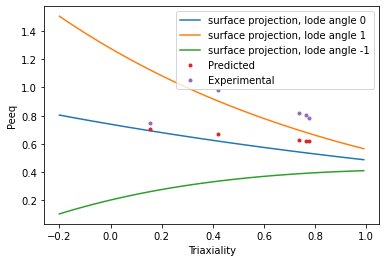

In [120]:
triax = np.arange(-0.2, 1, 0.01)
lode = 0
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * lode**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.legend()

In [121]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

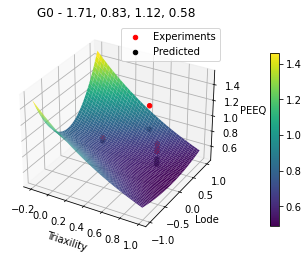

In [122]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experiments')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G0 - 1.71, 0.83, 1.12, 0.58')
ax.legend()